# Notebook 1 (máy local, OFFLINE) – Khám phá dữ liệu (EDA) và mô hình Baseline
**Đề tài 21 – ViTHSD: Phát hiện ngôn từ thù ghét theo đối tượng trên bình luận tiếng Việt** · Môn CMP169 – Trí tuệ Nhân tạo cơ bản

### Nguồn khung code
| Khung mẫu | Nguồn | Dùng cho mục |
|---|---|---|
| **A.** `02_classification.ipynb` – notebook chương 2 *Text Classification* của sách *Natural Language Processing with Transformers* (Tunstall, von Werra, Wolf – nhóm tác giả **Hugging Face**) | [github.com/nlp-with-transformers/notebooks](https://github.com/nlp-with-transformers/notebooks/blob/main/02_classification.ipynb) · Apache-2.0 | 2 (EDA), 4.1 (Dummy), 4.5 (Transformer làm bộ trích đặc trưng + LR), 5 (ma trận nhầm lẫn), 6 (phân tích lỗi theo loss) |
| **B.** `plot_document_classification_20newsgroups.py` – ví dụ chính thức *Classification of text documents using sparse features* của **scikit-learn 1.9.1** | [github.com/scikit-learn/scikit-learn](https://github.com/scikit-learn/scikit-learn/blob/1.9.1/examples/text/plot_document_classification_20newsgroups.py) · BSD-3 | 4.2 (TF-IDF, RidgeClassifier, feature effects), 4.3 (benchmark 8 bộ phân lớp) |

Bản gốc 2 file nằm trong thư mục `reference/` của project. Mô hình Transformer fine-tune (khung `run_classification.py`) ở **Notebook 2**.

### Bảng ánh xạ: khung mẫu → notebook này
| Mục | Trong khung mẫu | Trong notebook này | Thay đổi & lý do |
|---|---|---|---|
| 2.1 | A · *The Dataset*: `load_dataset(...)`; Sidebar: `load_dataset("csv", data_files=...)` | `load_dataset("csv", data_files=...)` đọc 3 file train/dev/test | File ViTHSD là CSV |
| 2.2 | A · *From Datasets to DataFrames*: `set_format("pandas")`, `label_int2str()` | Giữ nguyên, đổi số 0–3 thành tên mức | – |
| 2.3 | A · *Looking at the Class Distribution*: `value_counts().plot.barh()` | 5 biểu đồ, mỗi target một | ViTHSD có 5 nhãn, không phải 1 |
| 2.4 | A · *How Long Are Our Tweets?*: `"Words Per Tweet"`, `boxplot(by=...)` | `"Words Per Comment"` theo mức nặng nhất + ngoại lai IQR | – |
| 2.5 | (không có) | Chất lượng dữ liệu, trùng lặp giữa các tập, tương quan target | Yêu cầu EDA của môn; phát hiện rò rỉ dữ liệu |
| 4.1 | A · `DummyClassifier(strategy="most_frequent")`, `.score()` | Giữ nguyên, chạy cho 5 target | – |
| 4.2 | B · `TfidfVectorizer(sublinear_tf=True, max_df=0.5, min_df=5)`, `RidgeClassifier`, `ConfusionMatrixDisplay`, `plot_feature_effects()` | Giữ nguyên tham số, áp cho target `individual` (cũng 4 lớp như ví dụ) | Bỏ `stop_words="english"` (văn bản tiếng Việt) |
| 4.3 | B · `benchmark()` + 8 bộ phân lớp + biểu đồ điểm–thời gian | Giữ nguyên 8 bộ và tham số, bọc `MultiOutputClassifier` | 5 target; chấm F1 Target+Level trên **dev** thay vì accuracy trên test |
| 4.4 | (không có – nhóm tự cải tiến) | TF-IDF từ + ký tự, tinh chỉnh `C` × `class_weight`, 5-fold CV | Bắt teencode; xử lý mất cân bằng |
| 4.5 | A · *Transformers as Feature Extractors*: `AutoModel`, `extract_hidden_states()`, `LogisticRegression(max_iter=3000)` | Giữ nguyên với `uitnlp/visobert` | Token hóa ngay trong hàm, lô 64 câu (đỡ tốn bộ nhớ) |
| 5 | A · `plot_confusion_matrix()` (`normalize="true"`) | Giữ nguyên, vẽ cho 5 target trên test | – |
| 6 | A · *Error analysis*: loss từng mẫu, `sort_values("loss")` | Loss từng bình luận = tổng cross-entropy 5 target | Mô hình sklearn nên lấy xác suất từ `predict_proba` |

**Cách chạy:** máy local, **không cần Internet**. Bấm **Run → Run All Cells** (khoảng 3–5 phút). Mục 4.5 cần GPU NVIDIA và mô hình gốc trong `models/pretrained/visobert` (tải 1 lần bằng `2_TAI_MO_HINH_GOC.bat`); thiếu một trong hai thì mục 4.5 tự bỏ qua.
Kết quả (biểu đồ, bảng) lưu vào thư mục `outputs/`.


## 0. Chạy OFFLINE trên máy: bật chế độ offline và **khóa mạng**
Ô dưới chặn mọi kết nối Internet từ Python rồi thử vào một trang web. Thấy dòng *"KHÔNG truy cập được Internet"* là bằng chứng notebook chạy offline.
Dữ liệu đọc từ thư mục `data/`: 3 file train / dev / test **tải từ Hugging Face** `sonlam1102/vithsd` (bằng `2_TAI_MO_HINH_GOC.bat` lúc còn mạng, hoặc có sẵn trong `ViTHSD_ket_qua.zip` từ Colab).


In [1]:

# ===== 0. Bật chế độ offline + KHÓA mạng (chạy ô này ĐẦU TIÊN) =====
import os, sys, socket
from pathlib import Path
os.environ["HF_HUB_OFFLINE"] = "1"            # Hugging Face không gọi Internet
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_DATASETS_OFFLINE"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

def _blocked(*args, **kwargs):
    raise ConnectionError("Đã khóa Internet trong notebook này – mọi thứ phải chạy offline")
socket.socket.connect = _blocked              # chặn mọi kết nối mạng từ Python
socket.create_connection = _blocked
try:
    import urllib.request
    urllib.request.urlopen("https://huggingface.co", timeout=3)
    print("CẢNH BÁO: vẫn truy cập được Internet!")
except Exception as e:
    print("Kiểm tra mạng: KHÔNG truy cập được Internet ->", type(e).__name__, "| notebook chạy offline")

WORK = Path.cwd()
DATA_SOURCE = "Hugging Face – sonlam1102/vithsd (đã tải về thư mục data/)"
print("Thư mục làm việc:", WORK)


Kiểm tra mạng: KHÔNG truy cập được Internet -> URLError | notebook chạy offline
Thư mục làm việc: D:\ViTHSD


In [2]:
# ===== Thư viện và cấu hình chung =====
import warnings
warnings.filterwarnings("ignore")

import collections, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import KFold
import joblib

import common                      # file common.py cùng thư mục
from common import TARGETS, LEVELS, SEED, DATA_DIR, OUT_DIR, MODEL_DIR

np.random.seed(SEED)               # cố định seed -> chạy lại ra cùng kết quả
OUT_DIR.mkdir(exist_ok=True); MODEL_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 100)
plt.rcParams["figure.dpi"] = 110
print("Đã nạp thư viện. Seed =", SEED)

Đã nạp thư viện. Seed = 42


## Bước 1 – Định nghĩa bài toán
- **Input:** một bình luận mạng xã hội tiếng Việt (có teencode, emoji).
- **Output:** 5 nhãn ứng với 5 target (đối tượng bị nhắc tới): `individual` (cá nhân), `groups` (nhóm người),
  `religion/creed` (tôn giáo), `race/ethnicity` (dân tộc), `politics` (chính trị).
  Mỗi nhãn nhận 1 trong 4 giá trị: **0 = none (không nhắc), 1 = clean, 2 = offensive, 3 = hate**.
- **Loại bài toán:** Supervised Learning, phân lớp (classification) đa nhiệm: 5 bài toán phân lớp 4 lớp chạy song song.
- **Tiêu chí thành công:** chỉ số chính **F1 Target+Level (micro)** – một dự đoán chỉ đúng khi đúng cả target lẫn mức;
  báo cáo thêm F1 theo cách tính của paper (ViSoBERT 51,12%); phải vượt Dummy (đoán mò).
  Không dùng Accuracy làm chỉ số chính vì dữ liệu mất cân bằng nặng (thấy rõ ở mục 2.3 và 4.1).

## Bước 2 – Khám phá dữ liệu (EDA) · khung A: [`02_classification.ipynb`](https://github.com/nlp-with-transformers/notebooks/blob/main/02_classification.ipynb)
### 2.1 The Dataset – đọc dữ liệu bằng 🤗 Datasets
Khung đọc bộ `dair-ai/emotion` bằng `load_dataset(...)`. Phần *Sidebar* của khung chỉ cách đọc **file CSV trên máy**:
`load_dataset("csv", data_files=...)` → dùng đúng cách đó cho 3 file train / dev / test đã tải từ Hugging Face (`sonlam1102/vithsd`) ở ô 0.3
(đổi tên `dev` thành `validation` như trong khung).

In [3]:
from datasets import load_dataset

def find_file(split):
    """Đường dẫn file của 1 tập đã tải từ Hugging Face (tên dạng train.xlsx.csv, nội dung là CSV)."""
    return str(next(p for p in [DATA_DIR / f"{split}.xlsx.csv", DATA_DIR / f"{split}.csv"] if p.exists()))

data_files = {"train": find_file("train"), "validation": find_file("dev"), "test": find_file("test")}
vithsd = load_dataset("csv", data_files=data_files)        # khung: load_dataset("csv", data_files=...)
extra = [c for c in vithsd["train"].column_names if c.startswith("Unnamed")]
vithsd = vithsd.remove_columns(extra)                      # bỏ cột số thứ tự thừa (nếu có) do pandas ghi ra
vithsd

DatasetDict({
    train: Dataset({
        features: ['content', 'individual', 'groups', 'religion/creed', 'race/ethnicity', 'politics'],
        num_rows: 7000
    })
    validation: Dataset({
        features: ['content', 'individual', 'groups', 'religion/creed', 'race/ethnicity', 'politics'],
        num_rows: 1201
    })
    test: Dataset({
        features: ['content', 'individual', 'groups', 'religion/creed', 'race/ethnicity', 'politics'],
        num_rows: 1800
    })
})

In [4]:
train_ds = vithsd["train"]
print(train_ds.features)        # kiểu dữ liệu từng cột
train_ds[:3]                    # khung: train_ds[:5] – xem vài dòng đầu

{'content': Value('large_string'), 'individual': Value('int64'), 'groups': Value('int64'), 'religion/creed': Value('int64'), 'race/ethnicity': Value('int64'), 'politics': Value('int64')}


{'content': ['Chào nhà báo vũ hoàng Lân. Chào danh hài vũ trụ trần tiger:-)',
  'Anh Thi nào đi đăng ký rủ anh nhé.',
  'ở mỹ ns cái lồn gì k đc'],
 'individual': [2, 1, 0],
 'groups': [1, 0, 0],
 'religion/creed': [0, 0, 0],
 'race/ethnicity': [0, 0, 1],
 'politics': [0, 0, 0]}

### 2.2 From Datasets to DataFrames – chuyển sang pandas
Khung dùng `set_format(type="pandas")` để phân tích bằng pandas và hàm `label_int2str()` đổi nhãn số thành tên.

In [5]:
vithsd.set_format(type="pandas")
df = vithsd["train"][:]

def label_int2str(row):
    """0..3 -> none / clean / offensive / hate (khung dùng features["label"].int2str)."""
    return LEVELS[row]

for t in TARGETS:
    df[f"{t}_name"] = df[t].apply(label_int2str)
df.head()

,content,individual,groups,religion/creed,race/ethnicity,politics,individual_name,groups_name,religion/creed_name,race/ethnicity_name,politics_name
0,Chào nhà báo vũ hoàng Lân. Chào danh hài vũ trụ trần tiger:-),2,1,0,0,0,offensive,clean,none,none,none
1,Anh Thi nào đi đăng ký rủ anh nhé.,1,0,0,0,0,clean,none,none,none,none
2,ở mỹ ns cái lồn gì k đc,0,0,0,1,0,none,none,none,clean,none
3,"Thôn làm vậy là do thôn lầm, thôn lầm nên dân nó ghét, nó bật lại là thôn cái lù",0,0,0,0,0,none,none,none,none,none
4,Phạm Văn Lộc fuho trời nắng chóng mặt hả idol,1,0,0,0,0,clean,none,none,none,none


### 2.3 Looking at the Class Distribution – phân phối nhãn
Khung vẽ `value_counts(ascending=True).plot.barh()` cho 1 nhãn. ViTHSD có 5 target nên vẽ 5 biểu đồ (thang log để thấy cả lớp rất nhỏ).

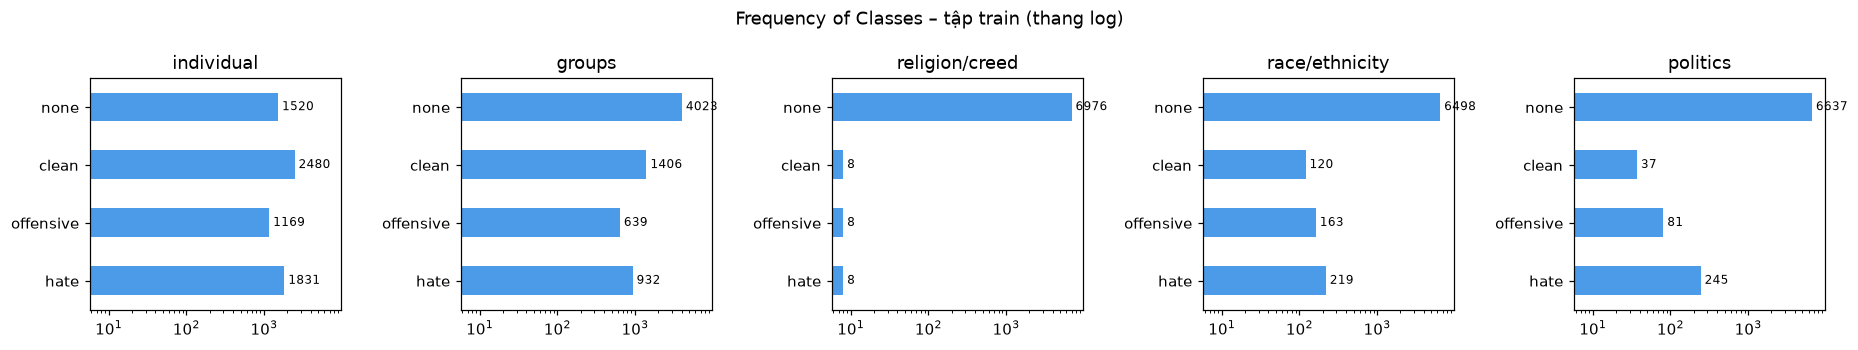

,none,clean,offensive,hate,có nhắc (1+2+3)
individual,1520,2480,1169,1831,5480
groups,4023,1406,639,932,2977
religion/creed,6976,8,8,8,24
race/ethnicity,6498,120,163,219,502
politics,6637,37,81,245,363


In [6]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.2), sharex=True)
for ax, t in zip(axes, TARGETS):
    counts = df[f"{t}_name"].value_counts(ascending=True).reindex(LEVELS[::-1], fill_value=0)
    counts.plot.barh(ax=ax, logx=True, color="#4c9be8")   # khung: df["label_name"].value_counts(ascending=True).plot.barh()
    for i, v in enumerate(counts):
        ax.text(max(v, 1), i, f" {v}", va="center", fontsize=8)
    ax.set_title(t); ax.set_ylabel("")
fig.suptitle("Frequency of Classes – tập train (thang log)")
plt.tight_layout(); plt.savefig(OUT_DIR / "eda_label_distribution.png"); plt.show()

dist = pd.DataFrame({t: df[t].value_counts().reindex(range(4), fill_value=0).values for t in TARGETS}, index=LEVELS).T
dist["có nhắc (1+2+3)"] = dist[["clean", "offensive", "hate"]].sum(1)
display(dist)

**Nhận xét:** mất cân bằng rất nặng: `religion/creed` chỉ có 24 bình luận có nhãn trong train (8 mỗi mức), `none` chiếm gần hết ở 4/5 target.
Khung A gợi ý 3 cách xử lý mất cân bằng (oversample lớp thiểu số, undersample lớp đa số, thu thêm dữ liệu) và nhắc chỉ làm **sau khi** chia train/test
để tránh rò rỉ. Đồ án dùng cách tương đương mà không phải nhân bản dữ liệu: **trọng số lớp (`class_weight="balanced"`)** ở mục 4.4.

### 2.4 How Long Are Our Comments? – độ dài bình luận
Khung đếm `"Words Per Tweet"` rồi vẽ boxplot theo nhãn. Ở đây đếm `"Words Per Comment"` theo **mức nặng nhất** của bình luận;
thêm phát hiện ngoại lai (outliers) bằng quy tắc IQR theo yêu cầu EDA của môn.

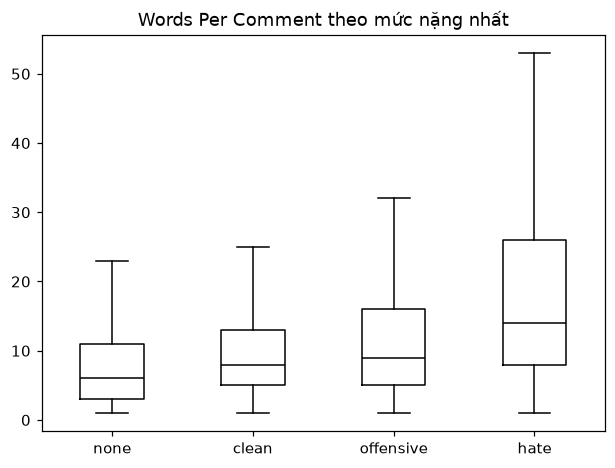

Số từ: trung bình 13.8, trung vị 9, 95% <= 41, dài nhất 172
Ngoại lai theo IQR (> 35 từ): 480 bình luận -> GIỮ LẠI vì là bình luận thật
Số từ trung bình theo mức nặng nhất: {'none': 8.4, 'clean': 10.6, 'offensive': 13.4, 'hate': 19.6}


In [7]:
df["Words Per Comment"] = df["content"].str.split().apply(len)           # khung: df["text"].str.split().apply(len)
df["mức nặng nhất"] = pd.Categorical(df[TARGETS].max(axis=1).map(label_int2str), categories=LEVELS, ordered=True)
df.boxplot("Words Per Comment", by="mức nặng nhất", grid=False, showfliers=False, color="black")
plt.suptitle(""); plt.xlabel(""); plt.title("Words Per Comment theo mức nặng nhất")
plt.savefig(OUT_DIR / "eda_length.png", bbox_inches="tight"); plt.show()

lengths = df["Words Per Comment"]
q1, q3 = np.percentile(lengths, [25, 75]); upper = q3 + 1.5 * (q3 - q1)   # quy tắc IQR
print(f"Số từ: trung bình {lengths.mean():.1f}, trung vị {lengths.median():.0f}, 95% <= {np.percentile(lengths, 95):.0f}, dài nhất {lengths.max()}")
print(f"Ngoại lai theo IQR (> {upper:.0f} từ): {(lengths > upper).sum()} bình luận -> GIỮ LẠI vì là bình luận thật")
print("Số từ trung bình theo mức nặng nhất:", df.groupby("mức nặng nhất", observed=True)["Words Per Comment"].mean().round(1).to_dict())

**Nhận xét:** bình luận ngắn (trung vị khoảng 9 từ) → giới hạn 128 token của Transformer là đủ (kiểm tra lại ở mục 4.5). Bình luận càng nặng càng dài.

### 2.5 Bổ sung ngoài khung: chất lượng dữ liệu, rò rỉ dữ liệu, tương quan target
Khung A không có phần này, nhưng yêu cầu EDA của môn có (giá trị thiếu, trùng lặp, tương quan) và nó **ảnh hưởng trực tiếp tới kết quả**.

In [8]:
import unicodedata
raw = {"train": vithsd["train"][:], "dev": vithsd["validation"][:], "test": vithsd["test"][:]}
vithsd.reset_format()                     # khung: emotions.reset_format()
for d in raw.values():
    d["content"] = d["content"].fillna("").astype(str)

rows = []
for name, d in raw.items():
    key = d["content"].map(common.dedup_key)
    rows.append({"tập": name, "số dòng": len(d), "rỗng": int((key == "").sum()),
                 "ô lỗi #ERROR!": int((key == "#error!").sum()),
                 "chưa chuẩn Unicode NFC": int((d["content"] != d["content"].map(lambda x: unicodedata.normalize("NFC", x))).sum()),
                 "dòng trùng văn bản": int(key.duplicated(keep=False).sum())})
display(pd.DataFrame(rows))

# Trùng lặp GIỮA các tập -> rò rỉ dữ liệu (data leakage)
k = {n: set(d["content"].map(common.dedup_key)) for n, d in raw.items()}
print("Văn bản trùng train-dev :", len(k["train"] & k["dev"]))
print("Văn bản trùng train-test:", len(k["train"] & k["test"]))

# Tương quan giữa các target (có nhắc / không nhắc)
mention = (raw["train"][TARGETS] > 0).astype(int)
display(mention.corr().round(2))
print("Số target trong 1 bình luận:", mention.sum(1).value_counts().sort_index().to_dict())

,tập,số dòng,rỗng,ô lỗi #ERROR!,chưa chuẩn Unicode NFC,dòng trùng văn bản
0,train,7000,0,4,189,360
1,dev,1201,0,0,21,14
2,test,1800,1,1,52,24


Văn bản trùng train-dev : 50
Văn bản trùng train-test: 84


,individual,groups,religion/creed,race/ethnicity,politics
individual,1.00,0.17,-0.02,-0.20,-0.19
groups,0.17,1.00,0.02,0.03,0.09
religion/creed,-0.02,0.02,1.00,0.04,0.07
race/ethnicity,-0.20,0.03,0.04,1.00,0.25
politics,-0.19,0.09,0.07,0.25,1.00


Số target trong 1 bình luận: {0: 883, 1: 3228, 2: 2586, 3: 269, 4: 31, 5: 3}


**Nhận xét:** có vài ô lỗi `#ERROR!` (do Excel), dòng trùng, và đặc biệt **bình luận trùng giữa train với dev/test**: giữ lại thì mô hình được
"nhìn trước" đáp án → điểm cao hơn thực tế. Các target tương quan yếu, một bình luận có thể nhắc nhiều target → tách 5 bài toán phân lớp là hợp lý.

## Bước 3 – Tiền xử lý
| Việc | Cách làm | Áp dụng cho |
|---|---|---|
| Chia tập | Giữ nguyên train/dev/test của tác giả (7.000 / 1.201 / 1.800) để so với paper; dev đóng vai **Validation** | – |
| Chuẩn hóa | Unicode NFC, link → `link`, ký tự lặp ≥ 3 lần → 2, gộp khoảng trắng; giữ emoji | Cả 3 tập (quy tắc cố định) |
| Làm sạch | Bỏ ô lỗi/rỗng, bỏ dòng trùng, **bỏ dòng train trùng với dev/test** | Chỉ train |
| Mã hóa văn bản | TF-IDF / tokenizer Transformer, **chỉ fit trên train** | Mục 4 |
| Mất cân bằng | `class_weight` (trọng số lớp) | Khi huấn luyện |

In [9]:
train, dev, test, clean_report = common.load_and_clean()
display(pd.DataFrame([clean_report]))
for s in ["Đẹppppp quáaaaa!!!!!!", "xem ở https://abc.com nè", "  nhiều    khoảng   trắng  "]:
    print(repr(s), "->", repr(common.normalize_text(s)))

Ytr, Ydv, Yte = common.label_matrix(train), common.label_matrix(dev), common.label_matrix(test)
print("\nMa trận nhãn (số bình luận, 5 target):", Ytr.shape, Ydv.shape, Yte.shape)

Train: 7000 -> 6785 dòng (bỏ 4 dòng lỗi, 76 dòng trùng, 135 dòng trùng với dev/test) | dev 1201 | test 1800


,train_goc,bo_dong_loi,bo_trung_hoan_toan,bo_trung_dev_test,train_con_lai,dev,test
0,7000,4,76,135,6785,1201,1800


'Đẹppppp quáaaaa!!!!!!' -> 'Đẹpp quáaa!!'
'xem ở https://abc.com nè' -> 'xem ở link nè'
'  nhiều    khoảng   trắng  ' -> 'nhiều khoảng trắng'

Ma trận nhãn (số bình luận, 5 target): (6785, 5) (1201, 5) (1800, 5)


## Bước 4 – Mô hình Baseline
### 4.1 Dummy classifier – mốc "đoán mò" · khung A
Khung: `DummyClassifier(strategy="most_frequent")` rồi `.score()` (accuracy). Chạy cho từng target và so **accuracy** với **F1**.

In [10]:
from sklearn.dummy import DummyClassifier

results_dev = {}                      # kết quả trên DEV để chọn mô hình
dummy_preds = {}
X_dummy_tr, X_dummy_dv, X_dummy_te = np.zeros((len(Ytr), 1)), np.zeros((len(Ydv), 1)), np.zeros((len(Yte), 1))
acc = {}
for strategy in ["most_frequent", "stratified"]:
    pred_dev, pred_te = np.zeros_like(Ydv), np.zeros_like(Yte)
    for j, t in enumerate(TARGETS):
        dummy_clf = DummyClassifier(strategy=strategy, random_state=SEED)   # khung: DummyClassifier(strategy="most_frequent")
        dummy_clf.fit(X_dummy_tr, Ytr[:, j])
        pred_dev[:, j] = dummy_clf.predict(X_dummy_dv); pred_te[:, j] = dummy_clf.predict(X_dummy_te)
        if strategy == "most_frequent":
            acc[t] = dummy_clf.score(X_dummy_dv, Ydv[:, j])                  # khung: dummy_clf.score(X_valid, y_valid)
    results_dev[f"Dummy ({strategy})"] = common.summarize(pred_dev, Ydv)
    dummy_preds[strategy] = pred_te
print("Accuracy của Dummy most_frequent trên dev:", {t: f"{a:.1%}" for t, a in acc.items()})
pd.DataFrame(results_dev).T

Accuracy của Dummy most_frequent trên dev: {'individual': '37.8%', 'groups': '57.0%', 'religion/creed': '99.3%', 'race/ethnicity': '93.8%', 'politics': '95.3%'}


,F1 T+L micro,P T+L micro,R T+L micro,F1 Target micro,F1 T+L (paper),F1 Target (paper),Macro-F1 TB 5 target,Toxic F1,Recall hate
Dummy (most_frequent),32.49,37.80,28.48,67.12,31.55,66.81,21.07,0.00,0.00
Dummy (stratified),24.03,23.86,24.22,60.27,22.30,56.24,25.24,54.62,42.63


**Nhận xét:** Dummy không đọc văn bản mà accuracy vẫn rất cao ở target hiếm (`religion/creed` khoảng 99%), trong khi
**Toxic F1 = 0** (không bao giờ phát hiện được bình luận độc hại) → **accuracy đánh lừa khi dữ liệu mất cân bằng**, nên đồ án dùng F1.
F1 Target+Level của Dummy most_frequent khoảng 30% vì nó luôn đoán `individual = clean` (mức phổ biến nhất): đây là **mốc tối thiểu** mọi mô hình phải vượt.

### 4.2 TF-IDF + RidgeClassifier · khung B: [ví dụ scikit-learn](https://github.com/scikit-learn/scikit-learn/blob/1.9.1/examples/text/plot_document_classification_20newsgroups.py)
Khung vector hóa bằng `TfidfVectorizer(sublinear_tf=True, max_df=0.5, min_df=5, stop_words="english")`, in thời gian và kích thước,
rồi huấn luyện `RidgeClassifier`, vẽ ma trận nhầm lẫn và **feature effects** (từ nào đẩy mô hình về lớp nào).
Ví dụ gốc có **4 lớp**, giống 4 mức của target `individual` → áp dụng cho target này. Bỏ `stop_words="english"` vì văn bản là tiếng Việt.
**Vectorizer chỉ `fit` trên train**, dev chỉ `transform` (chống rò rỉ).

In [11]:
from time import time
from sklearn.feature_extraction.text import TfidfVectorizer

def size_mb(docs):
    return sum(len(s.encode("utf-8")) for s in docs) / 1e6

# Khung B: phần vector hóa trong load_dataset()
t0 = time()
vectorizer = TfidfVectorizer(sublinear_tf=True, max_df=0.5, min_df=5)
X_train = vectorizer.fit_transform(train["text"])        # fit CHỈ trên train
duration_train = time() - t0
t0 = time()
X_dev = vectorizer.transform(dev["text"])               # dev chỉ transform
duration_test = time() - t0
feature_names = vectorizer.get_feature_names_out()

print(f"{len(train)} bình luận - {size_mb(train['text']):.2f}MB (train)")
print(f"{len(dev)} bình luận - {size_mb(dev['text']):.2f}MB (dev)")
print(f"vectorize train xong trong {duration_train:.3f}s")
print(f"n_samples: {X_train.shape[0]}, n_features: {X_train.shape[1]}")
print(f"vectorize dev xong trong {duration_test:.3f}s")

6785 bình luận - 0.51MB (train)
1201 bình luận - 0.09MB (dev)
vectorize train xong trong 0.116s
n_samples: 6785, n_features: 2023
vectorize dev xong trong 0.018s


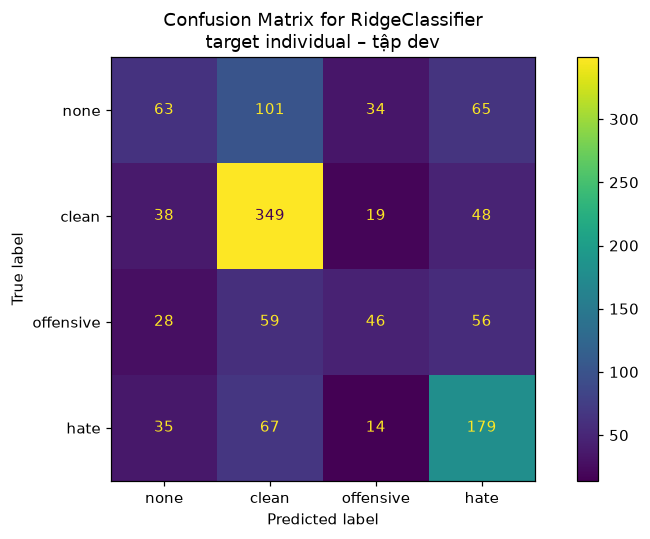

In [12]:
from sklearn.linear_model import RidgeClassifier
from sklearn.metrics import ConfusionMatrixDisplay

j_ind = TARGETS.index("individual")
y_train, y_dev = Ytr[:, j_ind], Ydv[:, j_ind]
target_names = LEVELS

clf = RidgeClassifier(tol=1e-2, solver="sparse_cg")      # khung B, giữ nguyên tham số
clf.fit(X_train, y_train)
pred = clf.predict(X_dev)

fig, ax = plt.subplots(figsize=(10, 5))
ConfusionMatrixDisplay.from_predictions(y_dev, pred, ax=ax, labels=list(range(4)), display_labels=target_names)
_ = ax.set_title(f"Confusion Matrix for {clf.__class__.__name__}\ntarget individual – tập dev")
plt.show()

top 5 keywords per class:
   none clean offensive   hate
0  nước   anh        vl    con
1   dân  thầy       đéo     nó
2   rồi    cô        mẹ    ngu
3  cộng    ơi       cái  thằng
4   mấy   quá       vcl    chó


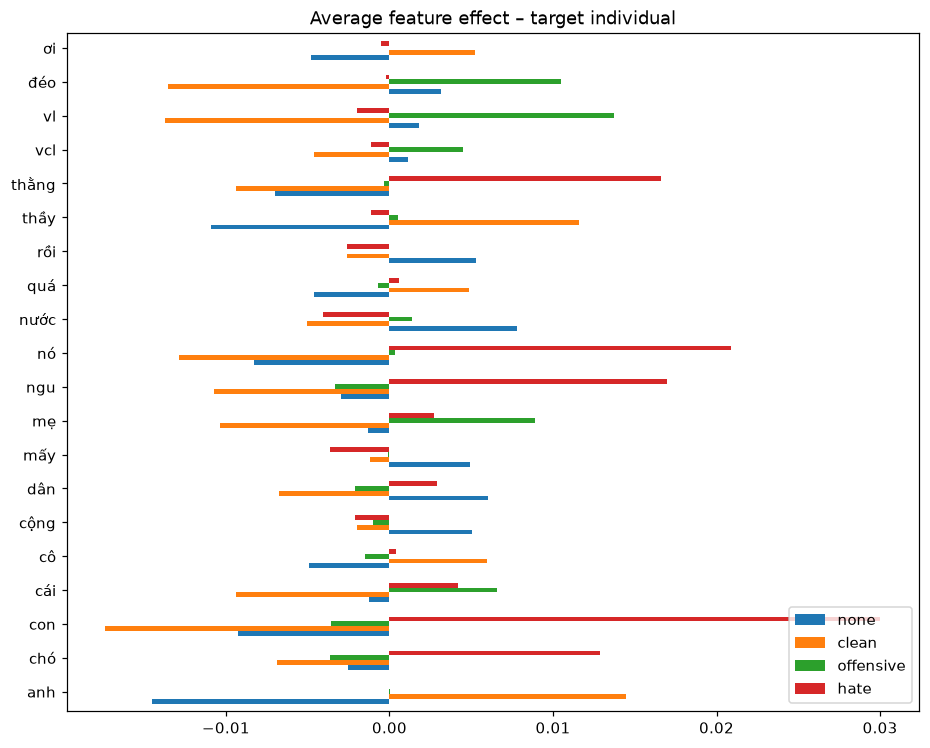

In [13]:
# Khung B: plot_feature_effects() – hệ số mô hình × tần suất xuất hiện trung bình của từ
def plot_feature_effects():
    # learned coefficients weighted by frequency of appearance
    average_feature_effects = clf.coef_ * np.asarray(X_train.mean(axis=0)).ravel()
    class_names = [target_names[c] for c in clf.classes_]

    for i, label in enumerate(class_names):
        top5 = np.argsort(average_feature_effects[i])[-5:][::-1]
        if i == 0:
            top = pd.DataFrame(feature_names[top5], columns=[label])
            top_indices = top5
        else:
            top[label] = feature_names[top5]
            top_indices = np.concatenate((top_indices, top5), axis=None)
    top_indices = np.unique(top_indices)
    predictive_words = feature_names[top_indices]

    # plot feature effects
    bar_size = 0.25
    padding = 0.75
    y_locs = np.arange(len(top_indices)) * (4 * bar_size + padding)

    fig, ax = plt.subplots(figsize=(10, 8))
    for i, label in enumerate(class_names):
        ax.barh(y_locs + (i - 2) * bar_size, average_feature_effects[i, top_indices], height=bar_size, label=label)
    ax.set(yticks=y_locs, yticklabels=predictive_words,
           ylim=[0 - 4 * bar_size, len(top_indices) * (4 * bar_size + padding) - 4 * bar_size])
    ax.legend(loc="lower right")

    print("top 5 keywords per class:")
    print(top)
    return ax

_ = plot_feature_effects().set_title("Average feature effect – target individual")
plt.savefig(OUT_DIR / "baseline_feature_effects.png", bbox_inches="tight"); plt.show()

**Nhận xét:** từ đẩy về `offensive` / `hate` là từ chửi thề, từ miệt thị và đại từ xưng hô thô ("vl", "đéo", "ngu", "thằng", "chó"),
từ đẩy về `clean` là xưng hô lịch sự ("anh", "thầy", "cô", "ơi"), còn `none` gắn với từ nói về số đông ("dân", "nước") → bình luận nhắc tới nhóm người
chứ không phải cá nhân. Mô hình túi từ (bag-of-words) phán đoán chủ yếu theo **từ khóa**, không hiểu ngữ cảnh → kiểm tra lại ở phần phân tích lỗi (mục 6).

### 4.3 Benchmarking classifiers – so sánh 8 bộ phân lớp · khung B
Giữ nguyên hàm `benchmark()` và **8 bộ phân lớp cùng tham số** của khung. Hai thay đổi:
1. Bọc `MultiOutputClassifier`: mỗi bộ phân lớp được nhân bản thành 5 mô hình, mỗi target một.
2. Điểm = **F1 Target+Level micro trên dev** (khung dùng accuracy trên test; đồ án chọn mô hình trên dev, giữ test cho lần đánh giá cuối).
Thêm `random_state=SEED` cho Random Forest và SGD để chạy lại ra cùng kết quả.

In [14]:
from sklearn.utils.extmath import density
from sklearn.multioutput import MultiOutputClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.svm import LinearSVC

def benchmark(clf, custom_name=False):
    print("_" * 80)
    print("Training: ")
    print(clf)
    model = MultiOutputClassifier(clf)                  # THAY ĐỔI 1: 5 target
    t0 = time()
    model.fit(X_train, Ytr)
    train_time = time() - t0
    print(f"train time: {train_time:.3}s")

    t0 = time()
    pred = model.predict(X_dev)
    test_time = time() - t0
    print(f"test time:  {test_time:.3}s")

    score = common.micro_prf(pred, Ydv)["f1"] * 100       # THAY ĐỔI 2: F1 Target+Level trên dev
    print(f"F1 T+L micro (dev): {score:.2f}%")

    first = model.estimators_[0]
    if hasattr(first, "coef_"):
        print(f"dimensionality: {first.coef_.shape[1]}")
        print(f"density: {density(first.coef_)}")
        print()

    print()
    clf_descr = str(custom_name) if custom_name else clf.__class__.__name__
    return clf_descr, score, train_time, test_time

results = []
for clf, name in (
    (LogisticRegression(C=5, max_iter=1000), "Logistic Regression"),
    (RidgeClassifier(alpha=1.0, solver="sparse_cg"), "Ridge Classifier"),
    (KNeighborsClassifier(n_neighbors=100), "kNN"),
    (RandomForestClassifier(random_state=SEED), "Random Forest"),
    # L2 penalty Linear SVC
    (LinearSVC(C=0.1, dual=False, max_iter=1000), "Linear SVC"),
    # L2 penalty Linear SGD
    (SGDClassifier(loss="log_loss", alpha=1e-4, n_iter_no_change=3, early_stopping=True, random_state=SEED), "log-loss SGD"),
    # NearestCentroid (aka Rocchio classifier)
    (NearestCentroid(), "NearestCentroid"),
    # Sparse naive Bayes classifier
    (ComplementNB(alpha=0.1), "Complement naive Bayes"),
):
    print("=" * 80)
    print(name)
    results.append(benchmark(clf, name))

Logistic Regression
________________________________________________________________________________
Training: 
LogisticRegression(C=5, max_iter=1000)
train time: 1.0s
test time:  0.00199s
F1 T+L micro (dev): 48.99%
dimensionality: 2023
density: 1.0


Ridge Classifier
________________________________________________________________________________
Training: 
RidgeClassifier(solver='sparse_cg')
train time: 0.217s
test time:  0.00201s
F1 T+L micro (dev): 49.02%
dimensionality: 2023
density: 1.0


kNN
________________________________________________________________________________
Training: 
KNeighborsClassifier(n_neighbors=100)
train time: 0.01s
test time:  0.7s
F1 T+L micro (dev): 0.13%

Random Forest
________________________________________________________________________________
Training: 
RandomForestClassifier(random_state=42)
train time: 20.6s
test time:  0.557s
F1 T+L micro (dev): 49.34%

Linear SVC
________________________________________________________________________________
T

,bộ phân lớp,F1 T+L dev,train time (s),test time (s)
3,Random Forest,49.336,20.580,0.557
1,Ridge Classifier,49.017,0.217,0.002
0,Logistic Regression,48.986,1.003,0.002
5,log-loss SGD,48.519,0.237,0.002
4,Linear SVC,47.883,0.168,0.003
6,NearestCentroid,45.026,0.966,0.064
7,Complement naive Bayes,41.838,0.015,0.001
2,kNN,0.125,0.010,0.700


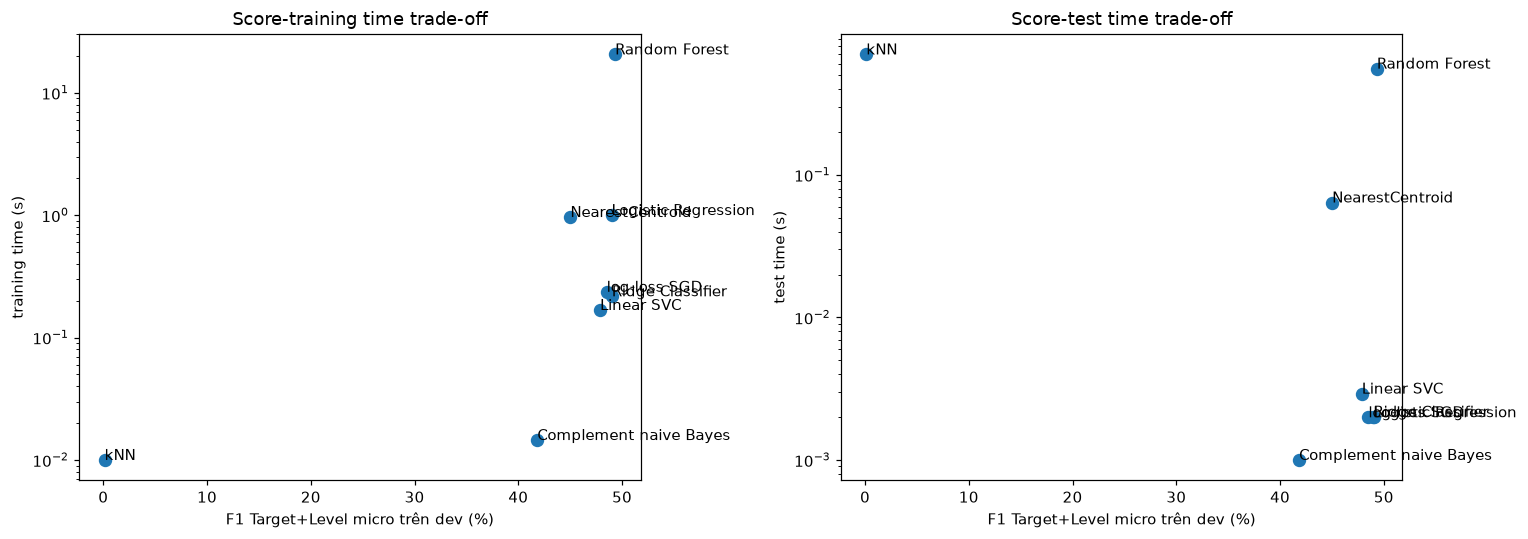

In [15]:
# Khung B: Plot accuracy, training and test time of each classifier (gộp 2 hình thành 1)
bench = pd.DataFrame(results, columns=["bộ phân lớp", "F1 T+L dev", "train time (s)", "test time (s)"])
display(bench.sort_values("F1 T+L dev", ascending=False).round(3))
clf_names, score, training_time, test_time = [list(bench[c]) for c in bench.columns]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.scatter(score, training_time, s=60)
ax1.set(title="Score-training time trade-off", yscale="log", xlabel="F1 Target+Level micro trên dev (%)", ylabel="training time (s)")
ax2.scatter(score, test_time, s=60)
ax2.set(title="Score-test time trade-off", yscale="log", xlabel="F1 Target+Level micro trên dev (%)", ylabel="test time (s)")
for i, txt in enumerate(clf_names):
    ax1.annotate(txt, (score[i], training_time[i]))
    ax2.annotate(txt, (score[i], test_time[i]))
plt.tight_layout(); plt.savefig(OUT_DIR / "baseline_benchmark.png"); plt.show()

**Nhận xét (so với kết luận của khung B):**
- Nhóm dẫn đầu (Random Forest, Ridge, Logistic Regression, SGD) chỉ chênh nhau khoảng 1 điểm F1, nhưng **Random Forest train chậm hơn hàng chục lần**
  và dự đoán chậm hơn hơn 100 lần → giống khung B: với đặc trưng văn bản nhiều chiều, mô hình tuyến tính là lựa chọn hợp lý.
- **kNN gần như bằng 0**: 100 láng giềng bỏ phiếu theo đa số nên gần như luôn đoán `none` (mất cân bằng + "lời nguyền số chiều" mà khung B nhắc tới).
- Đồ án chọn **Logistic Regression** để cải tiến tiếp: thuộc nhóm dẫn đầu, train nhanh, và cho **xác suất** (`predict_proba`) – cần cho đường ROC/PR,
  phân tích lỗi theo loss và hiển thị độ tin cậy khi demo (Ridge, Linear SVC không có `predict_proba`).

### 4.4 Cải tiến baseline (nhóm tự làm, ngoài khung): TF-IDF từ + ký tự, tinh chỉnh trên dev
- **Đặc trưng:** n-gram **từ** (1–2, giữ cả từ 1 ký tự) ghép n-gram **ký tự** (2–5) → bắt được teencode, từ viết sai ("nguuu", "n.g.u").
- **Tinh chỉnh:** thử `C` (độ mạnh regularization: C nhỏ = phạt mạnh = mô hình đơn giản) × `class_weight` (none / balanced) trên **dev**;
  đo thêm F1 trên **train** để nhìn thấy underfitting / overfitting. **Tập test không dùng ở bước này.**
- 3 hàm `build_vectorizer`, `fit_lr`, `predict_proba_lr` nằm trong `common.py` để bản demo offline tái tạo đúng mô hình này.

Số đặc trưng TF-IDF từ + ký tự: 37,981  (1.2 giây)


,C,class_weight,F1 train,F1 dev
5,1.0,balanced,86.30,52.19
7,2.0,balanced,91.64,52.08
3,0.5,balanced,80.16,51.91
8,4.0,none,97.12,51.84
4,1.0,none,80.28,51.63


=> Cấu hình tốt nhất trên dev: C = 1.0, class_weight = balanced


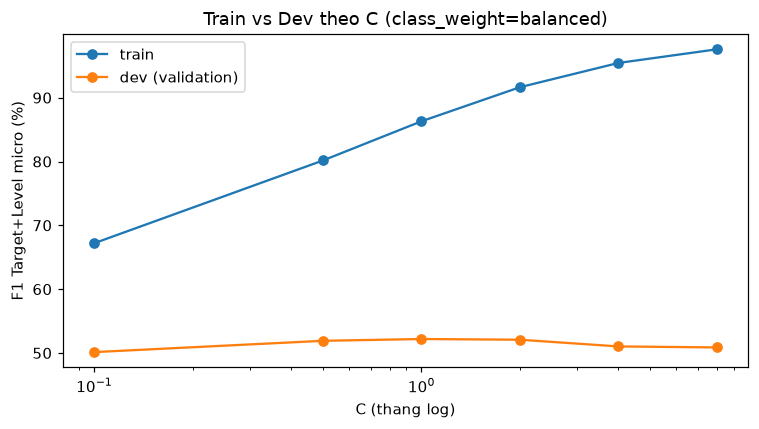

In [16]:
build_vectorizer, fit_lr, predict_proba_lr = common.build_vectorizer, common.fit_lr, common.predict_proba_lr

t0 = time()
vec = build_vectorizer()
Xtr = vec.fit_transform(train["text"])    # FIT chỉ trên train
Xdv = vec.transform(dev["text"])          # dev, test chỉ transform
Xte = vec.transform(test["text"])
print(f"Số đặc trưng TF-IDF từ + ký tự: {Xtr.shape[1]:,}  ({time() - t0:.1f} giây)")

grid = []
for C in [0.1, 0.5, 1, 2, 4, 8]:
    for cw in [None, "balanced"]:
        models = fit_lr(Xtr, Ytr, C, cw)
        f1_tr = common.micro_prf(predict_proba_lr(models, Xtr).argmax(-1), Ytr)["f1"] * 100
        f1_dv = common.micro_prf(predict_proba_lr(models, Xdv).argmax(-1), Ydv)["f1"] * 100
        grid.append({"C": C, "class_weight": cw or "none", "F1 train": round(f1_tr, 2), "F1 dev": round(f1_dv, 2)})
grid = pd.DataFrame(grid)
display(grid.sort_values("F1 dev", ascending=False).head())

best = grid.sort_values("F1 dev", ascending=False).iloc[0]
BEST_C, BEST_CW = float(best["C"]), (None if best["class_weight"] == "none" else best["class_weight"])
print(f"=> Cấu hình tốt nhất trên dev: C = {BEST_C}, class_weight = {best['class_weight']}")

fig, ax = plt.subplots(figsize=(7, 4))
g = grid[grid["class_weight"] == best["class_weight"]]
ax.plot(g["C"], g["F1 train"], "o-", label="train"); ax.plot(g["C"], g["F1 dev"], "o-", label="dev (validation)")
ax.set_xscale("log"); ax.set_xlabel("C (thang log)"); ax.set_ylabel("F1 Target+Level micro (%)")
ax.set_title(f"Train vs Dev theo C (class_weight={best['class_weight']})"); ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "baseline_train_vs_dev.png"); plt.show()

**Nhận xét:** C càng lớn thì F1 train càng tăng (học thuộc) nhưng F1 dev chỉ tăng tới một điểm rồi đi ngang/giảm:
C nhỏ → **underfitting**, C lớn → **overfitting**. Chọn điểm có F1 dev cao nhất.

In [17]:
# Kiểm định chéo 5-fold trên train: báo cáo độ ổn định (trung bình ± độ lệch chuẩn).
# Vectorizer fit lại trong TỪNG fold để không rò rỉ dữ liệu.
cv_scores = []
for k, (tr_idx, va_idx) in enumerate(KFold(n_splits=5, shuffle=True, random_state=SEED).split(train)):
    v = build_vectorizer()
    Xa = v.fit_transform(train["text"].iloc[tr_idx]); Xb = v.transform(train["text"].iloc[va_idx])
    ms = fit_lr(Xa, Ytr[tr_idx], BEST_C, BEST_CW)
    cv_scores.append(common.micro_prf(predict_proba_lr(ms, Xb).argmax(-1), Ytr[va_idx])["f1"] * 100)
    print(f"Fold {k + 1}: F1 = {cv_scores[-1]:.2f}%")
print(f"=> 5-fold CV: F1 Target+Level micro = {np.mean(cv_scores):.2f} ± {np.std(cv_scores):.2f} %")

lr_models = fit_lr(Xtr, Ytr, BEST_C, BEST_CW)          # mô hình baseline cuối cùng
prob_dv = predict_proba_lr(lr_models, Xdv)
results_dev["TF-IDF + LR"] = common.summarize(prob_dv.argmax(-1), Ydv, prob_dv)

Fold 1: F1 = 48.77%
Fold 2: F1 = 50.26%
Fold 3: F1 = 48.51%
Fold 4: F1 = 49.03%
Fold 5: F1 = 49.91%
=> 5-fold CV: F1 Target+Level micro = 49.30 ± 0.67 %


### 4.5 Transformer làm bộ trích đặc trưng (feature extractor) · khung A: *Transformers as Feature Extractors*
Khung A dùng Transformer **đóng băng** (không train lại): lấy vector của token đầu tiên (`[CLS]`, ở ViSoBERT là `<s>`) làm đặc trưng,
rồi huấn luyện `LogisticRegression(max_iter=3000)` trên đó. Đây là bước trung gian giữa TF-IDF và **fine-tune** toàn bộ mô hình ở Notebook 2.
- Mô hình: `uitnlp/visobert` (không cần tách từ). Trên máy local đọc từ `models/pretrained/visobert`.
- **Cần GPU** (Colab T4: khoảng 1 phút; CPU: khoảng 15–30 phút) → mặc định chỉ chạy khi có GPU. Muốn chạy bằng CPU thì đặt `RUN_FEATURE_EXTRACTION = True`.

In [18]:
# ===== Khung A: nạp tokenizer + mô hình =====
import os
import torch
from transformers import AutoModel, AutoTokenizer
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()

local_copy = MODEL_DIR / "pretrained" / "visobert"                 # bản đã tải sẵn trên máy (bản local)
model_ckpt = str(local_copy) if (local_copy / "config.json").exists() else "uitnlp/visobert"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # khung A, giữ nguyên

RUN_FEATURE_EXTRACTION = torch.cuda.is_available()                # đổi thành True để chạy bằng CPU (chậm)
HAVE_TRANSFORMER = not (os.environ.get("HF_HUB_OFFLINE") == "1" and model_ckpt == "uitnlp/visobert")
if HAVE_TRANSFORMER:
    tokenizer = AutoTokenizer.from_pretrained(model_ckpt)           # khung: AutoTokenizer.from_pretrained(model_ckpt)
    print("Mô hình:", model_ckpt, "| thiết bị:", device, "| trích đặc trưng:", RUN_FEATURE_EXTRACTION)
else:
    RUN_FEATURE_EXTRACTION = False
    print("Chưa có models/pretrained/visobert -> bỏ qua mục 4.5 (khi có mạng chạy 2_TAI_MO_HINH_GOC.bat)")

Mô hình: D:\ViTHSD\models\pretrained\visobert | thiết bị: cuda | trích đặc trưng: True


In [19]:
# ===== Khung A – Tokenization: xem tokenizer cắt câu thế nào + số token mỗi bình luận =====
if HAVE_TRANSFORMER:
    text = "bài hát này hay quá"
    encoded_text = tokenizer(text)
    print(encoded_text)
    tokens = tokenizer.convert_ids_to_tokens(encoded_text.input_ids)
    print(tokens)
    print(tokenizer.convert_tokens_to_string(tokens))
    print("vocab_size:", tokenizer.vocab_size, "| model_input_names:", tokenizer.model_input_names)

    # Bổ sung: phân phối số token -> kiểm tra max_length = 128 dùng ở Notebook 2
    n_tok = np.array([len(ids) for ids in tokenizer(list(train["text"]))["input_ids"]])
    print(f"Số token/bình luận: trung vị {np.median(n_tok):.0f}, 95% <= {np.percentile(n_tok, 95):.0f}, "
          f"bị cắt nếu max_length=128: {(n_tok > 128).mean():.1%}")

{'input_ids': [0, 14, 96, 13, 238, 75, 13, 46, 115, 2], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}
['<s>', '▁b', 'ài', '▁h', 'át', '▁này', '▁h', 'ay', '▁quá', '</s>']
<s> bài hát này hay quá</s>
vocab_size: 15002 | model_input_names: ['input_ids', 'attention_mask']
Số token/bình luận: trung vị 18, 95% <= 74, bị cắt nếu max_length=128: 0.7%


In [ ]:
# ===== Khung A – extract_hidden_states(): vector [CLS] của từng bình luận =====
if RUN_FEATURE_EXTRACTION:
    from datasets import Dataset, DatasetDict
    model = AutoModel.from_pretrained(model_ckpt, add_pooling_layer=False).to(device).eval()   # khung: AutoModel.from_pretrained(model_ckpt).to(device)

    def extract_hidden_states(batch):
        # THAY ĐỔI: token hóa ngay trong hàm, đệm (padding) theo từng lô -> đỡ tốn bộ nhớ
        inputs = tokenizer(batch["text"], padding=True, truncation=True, max_length=128, return_tensors="pt")
        # Place model inputs on the GPU
        inputs = {k: v.to(device) for k, v in inputs.items() if k in tokenizer.model_input_names}
        # Extract last hidden states
        with torch.no_grad():
            last_hidden_state = model(**inputs).last_hidden_state
        # Return vector for [CLS] token
        return {"hidden_state": last_hidden_state[:, 0].cpu().numpy()}

    vithsd_clean = DatasetDict({name: Dataset.from_pandas(d[["text"]].reset_index(drop=True))
                                for name, d in [("train", train), ("validation", dev), ("test", test)]})
    t0 = time()
    vithsd_hidden = vithsd_clean.map(extract_hidden_states, batched=True, batch_size=64)
    print(f"Trích đặc trưng xong trong {time() - t0:.0f} giây")

    # Khung A: tạo ma trận đặc trưng
    X_train_h = np.array(vithsd_hidden["train"]["hidden_state"], dtype=np.float32)
    X_valid_h = np.array(vithsd_hidden["validation"]["hidden_state"], dtype=np.float32)
    X_test_h = np.array(vithsd_hidden["test"]["hidden_state"], dtype=np.float32)
    print("Kích thước:", X_train_h.shape, X_valid_h.shape, X_test_h.shape)
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
else:
    print("Bỏ qua trích đặc trưng (không có GPU). Đặt RUN_FEATURE_EXTRACTION = True ở ô trên nếu muốn chạy bằng CPU.")

In [ ]:
# ===== Khung A – Training a simple classifier: LogisticRegression(max_iter=3000) trên vector [CLS] =====
if RUN_FEATURE_EXTRACTION:
    # common.fit_lr = 5 LogisticRegression(max_iter=3000), mỗi target một; dùng cùng class_weight đã chọn ở 4.4
    hidden_lr = fit_lr(X_train_h, Ytr, 1.0, BEST_CW)
    prob_dv_h = predict_proba_lr(hidden_lr, X_valid_h)
    results_dev["ViSoBERT (đặc trưng) + LR"] = common.summarize(prob_dv_h.argmax(-1), Ydv, prob_dv_h)
    print("Xong. F1 T+L micro (dev):", results_dev["ViSoBERT (đặc trưng) + LR"]["F1 T+L micro"])

### 4.6 So sánh các baseline trên dev

In [ ]:
table_dev = pd.DataFrame(results_dev).T
display(table_dev)

**Nhận xét:** Transformer **đóng băng** chưa chắc vượt TF-IDF: vector `[CLS]` chưa từng được dạy cho bài toán này.
Khung A kết luận: **fine-tune** toàn bộ mô hình cho kết quả tốt hơn hẳn, còn trích đặc trưng là phương án dung hòa khi thiếu GPU → fine-tune ở Notebook 2.

## Bước 5 – Đánh giá trên tập test (chỉ một lần)
Mô hình đã chọn xong trên dev, giờ mới đánh giá **một lần** trên test.

In [ ]:
prob_te = predict_proba_lr(lr_models, Xte)
pred_te = prob_te.argmax(-1)
results_test = {
    "Dummy (most_frequent)": common.summarize(dummy_preds["most_frequent"], Yte),
    "Dummy (stratified)": common.summarize(dummy_preds["stratified"], Yte),
    "TF-IDF + LR": common.summarize(pred_te, Yte, prob_te),
}
if RUN_FEATURE_EXTRACTION:
    prob_te_h = predict_proba_lr(hidden_lr, X_test_h)
    results_test["ViSoBERT (đặc trưng) + LR"] = common.summarize(prob_te_h.argmax(-1), Yte, prob_te_h)
table_test = pd.DataFrame(results_test).T
display(table_test)
print("Kết quả theo từng target của TF-IDF + LR:")
display(common.per_target_report(pred_te, Yte))
common.print_classification_reports(pred_te, Yte)

### 5.1 Ma trận nhầm lẫn chuẩn hóa · khung A: `plot_confusion_matrix()`

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

def plot_confusion_matrix(y_preds, y_true, labels, ax=None, title="Normalized confusion matrix"):
    """Khung A, thêm tham số ax/title để vẽ 5 target trên 1 hình."""
    cm = confusion_matrix(y_true, y_preds, normalize="true", labels=list(range(len(labels))))
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(cmap="Blues", values_format=".2f", ax=ax, colorbar=False)
    ax.set_title(title)

fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for j, t in enumerate(TARGETS):
    plot_confusion_matrix(pred_te[:, j], Yte[:, j], LEVELS, ax=axes.ravel()[j], title=t)
axes.ravel()[5].axis("off")
axes.ravel()[5].text(0.05, 0.5, "Hàng = nhãn thật\nCột = dự đoán\nSố = tỷ lệ trên mỗi hàng\n(normalize=\"true\")", fontsize=12, va="center")
fig.suptitle("TF-IDF + LR – tập test")
plt.tight_layout(); plt.savefig(OUT_DIR / "baseline_confusion_test.png"); plt.show()

### 5.2 ROC và Precision-Recall (bài toán toxic ở mức bình luận)

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
y = (Yte >= 2).any(1).astype(int)              # bình luận có target ở mức offensive/hate
score = prob_te[:, :, 2:].sum(2).max(1)
fpr, tpr, _ = roc_curve(y, score); p, r, _ = precision_recall_curve(y, score)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].set_title(f"ROC – AUC = {roc_auc_score(y, score):.3f}"); ax[0].set_xlabel("False Positive Rate"); ax[0].set_ylabel("True Positive Rate (Recall)")
ax[1].plot(r, p); ax[1].axhline(y.mean(), ls="--", color="gray", label=f"ngẫu nhiên = {y.mean():.2f}")
ax[1].set_title(f"Precision-Recall – AP = {average_precision_score(y, score):.3f}"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "baseline_roc_pr_test.png"); plt.show()

**Nhận xét cần viết vào báo cáo:** TF-IDF + LR vượt xa Dummy ở F1 Target+Level → mô hình thật sự học được.
Dummy most_frequent vẫn có F1 Target khá cao vì luôn đoán `individual` = clean → chỉ số chính phải là Target+Level.
`religion/creed` gần như chỉ đúng lớp `none` vì quá ít mẫu train.

## Bước 6 – Phân tích lỗi (trên dev) · khung A: *Error analysis*
Khung A tính **loss của từng mẫu** rồi sắp xếp: loss **cao nhất** = mô hình sai mà tự tin, hoặc **nhãn bị gán sai**;
loss **thấp nhất** = mô hình chắc chắn nhất. Ở đây loss của 1 bình luận = tổng cross-entropy của 5 target,
tính từ xác suất `predict_proba` (khung tính từ logit của Transformer). Phân tích trên **dev** để không "nhìn trộm" test.

In [ ]:
def loss_per_sample(prob, Y):
    """Cross-entropy từng bình luận = tổng -log p(mức đúng) trên 5 target (khung: cross_entropy(..., reduction="none"))."""
    p_true = np.take_along_axis(prob, Y[:, :, None], axis=2)[:, :, 0]
    return -np.log(np.clip(p_true, 1e-12, 1)).sum(1)

pred_dv = prob_dv.argmax(-1)
# Khung A: df_test = ...[["text", "label", "predicted_label", "loss"]]
df_dev = dev[["content"]].copy()
df_dev["label"] = [common.levels_to_text(r) for r in Ydv]
df_dev["predicted_label"] = [common.levels_to_text(r) for r in pred_dv]
df_dev["loss"] = loss_per_sample(prob_dv, Ydv).round(3)
df_dev["số target sai"] = (pred_dv != Ydv).sum(1)
df_dev.to_csv(OUT_DIR / "baseline_errors_dev.csv", encoding="utf-8-sig", index=False)

# Thống kê bổ sung (ngoài khung)
pairs = collections.Counter((LEVELS[a], LEVELS[b]) for a, b in zip(Ydv[:, 0], pred_dv[:, 0]) if a != b)
print("individual – nhầm (thật -> đoán) nhiều nhất:", pairs.most_common(5))
bins = pd.cut(dev["content"].str.split().str.len(), [0, 5, 10, 20, 40, 1000], labels=["1-5", "6-10", "11-20", "21-40", ">40"])
print("% bình luận có target sai theo độ dài:", ((df_dev["số target sai"] > 0).groupby(bins, observed=True).mean() * 100).round(1).to_dict())

**10 bình luận có loss cao nhất** (khung: `df_test.sort_values("loss", ascending=False).head(10)`)

In [ ]:
df_dev.sort_values("loss", ascending=False).head(10)

**10 bình luận có loss thấp nhất** (khung: `df_test.sort_values("loss", ascending=True).head(10)`)

In [ ]:
df_dev.sort_values("loss", ascending=True).head(10)

**Gợi ý xếp nhóm lỗi** (đọc 2 bảng trên và đếm): nhãn có vẻ sai · teencode / viết không dấu · mỉa mai, ẩn ý · nhầm offensive ↔ hate ·
nhầm individual ↔ groups · câu quá ngắn. Mô hình TF-IDF chỉ nhìn từ khóa, không hiểu ngữ cảnh → lý do fine-tune Transformer ở Notebook 2.
Toàn bộ dev kèm loss lưu ở `outputs/baseline_errors_dev.csv`.

## Lưu mô hình và kết quả (thư mục models/ và outputs/)

In [ ]:
joblib.dump({"vectorizer": vec, "models": lr_models, "C": BEST_C, "class_weight": BEST_CW},
            MODEL_DIR / "baseline_tfidf_lr.joblib")
table_test.to_csv(OUT_DIR / "baseline_test_results.csv", encoding="utf-8-sig")
bench.to_csv(OUT_DIR / "baseline_benchmark_dev.csv", encoding="utf-8-sig", index=False)
json.dump({"cv_f1_mean": float(np.mean(cv_scores)), "cv_f1_std": float(np.std(cv_scores)),
           "best_C": BEST_C, "best_class_weight": str(BEST_CW), "clean_report": clean_report,
           "feature_extraction": bool(RUN_FEATURE_EXTRACTION), "data_source": DATA_SOURCE,
           "templates": ["nlp-with-transformers/notebooks 02_classification.ipynb",
                         "scikit-learn 1.9.1 examples/text/plot_document_classification_20newsgroups.py"]},
          open(OUT_DIR / "baseline_info.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print("Đã lưu: models/baseline_tfidf_lr.joblib, outputs/baseline_test_results.csv, outputs/baseline_info.json")

# Thử dự đoán câu mới
def predict_baseline(texts):
    X = vec.transform([common.normalize_text(t) for t in texts])
    for t, row in zip(texts, predict_proba_lr(lr_models, X).argmax(-1)):
        print(t, "->", common.levels_to_text(row))
predict_baseline(["bài hát này hay quá", "thằng này ngu thật"])